# Lab 3 — Millions of TVs, Who Is Watching?
Name: Zhmurko Vira,  | Group: KM-41

## Setup

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
import warnings

started = time.perf_counter()
packages = {"kagglehub": "kagglehub>=0.3,<2", "pandas": "pandas>=2.2,<3",
            "numpy": "numpy>=1.26,<3", "matplotlib": "matplotlib>=3.8,<4", "pyarrow": "pyarrow>=15"}
missing = [v for k, v in packages.items() if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
warnings.filterwarnings("ignore", message="IProgress not found.*")
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA = os.environ.get("LAB3_DATA_DIR")
if DATA is None:
    DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:.1f}")
days = pd.date_range("2024-10-14", "2024-10-27")
begin, end = days[0]+pd.Timedelta(hours=6), days[-1]+pd.Timedelta(days=1,hours=6)
for c in ["start_utc", "end_utc"]:
    acr_sessions[c.replace("utc", "ts")] = pd.to_datetime(acr_sessions[c], utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
for column in ["hashed_ip", "session_type", "network_code", "input_source"]:
    acr_sessions[column] = acr_sessions[column].astype("category")
acr_sessions = acr_sessions.drop(columns=["start_utc", "end_utc"])
for f in [programs, viewings]:
    f["start_ts"] = pd.to_datetime(f.start_ts)
    f["end_ts"] = pd.to_datetime(f.end_ts)
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights.broadcast_date)
programs["broadcast_date"] = pd.to_datetime(programs.broadcast_date)
assert acr_sessions.session_id.is_unique
assert hh_attributes.household_id.is_unique

def day_pieces(frame):
    current = frame.loc[frame.start_ts.lt(end) & frame.end_ts.gt(begin)].copy()
    current["start_ts"] = current.start_ts.clip(lower=begin)
    current["end_ts"] = current.end_ts.clip(upper=end)
    parts = []
    while not current.empty:
        dates = (current.start_ts-pd.Timedelta(hours=6)).dt.normalize()
        stops = pd.concat([current.end_ts, dates+pd.Timedelta(days=1,hours=6)],axis=1).min(axis=1)
        chunk = current.copy()
        chunk["end_ts"], chunk["broadcast_date"] = stops, dates
        chunk["hours"] = (stops-current.start_ts).dt.total_seconds()/3600
        parts.append(chunk)
        current["start_ts"] = stops
        current = current.loc[current.start_ts.lt(current.end_ts)].copy()
    return pd.concat(parts,ignore_index=True)

raw = acr_sessions.loc[acr_sessions.start_ts.lt(end) & acr_sessions.end_ts.gt(begin)].copy()
raw["seconds"] = (raw.end_ts-raw.start_ts).dt.total_seconds()
edited = raw.loc[raw.seconds.ge(60)].copy()
acr = day_pieces(edited)
in_tab = acr[["tv_id", "broadcast_date"]].drop_duplicates()
tv_counts = in_tab.groupby("broadcast_date").tv_id.nunique().reindex(days,fill_value=0)
raw_pieces = day_pieces(raw)
raw_tv_days = raw_pieces[["tv_id", "broadcast_date"]].drop_duplicates()
decoded = viewer_attributes.merge(attributes,on="attr_id",how="left",validate="many_to_one")
assert decoded.attr_name.notna().all()
hh_days = daily_weights.loc[daily_weights.resp_type.eq("H") & daily_weights.broadcast_date.isin(days)].copy()
hh_monthly = hh_days.groupby("respondent_id").weight.mean()
panel_meta = pd.DataFrame(index=hh_monthly.index)
for label, group in [("region", "Census region"), ("income_band", "Household income")]:
    panel_meta[label] = decoded.loc[decoded.attr_group.eq(group)].set_index("respondent_id").attr_name
panel_meta["weight"] = hh_monthly
assert panel_meta.notna().all().all()
TEN = set(programs.network_code.unique())
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
live = acr.loc[acr.session_type.eq("live") & acr.network_code.isin(TEN)].copy()

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Five questions

**Answer:**

| File | Grain | Key | Coverage | Weight | Provenance |
|---|---|---|---|---|---|
| acr_sessions | One continuous session on one TV | session_id; tv_id identifies the set | Opted-in smart TVs, October 14–27; recognized networks, DVR, apps and unknown screen use | None; one TV counts once | Synthetic vendor feed based on ACR screen fingerprints; recognition depends on its reference library |
| Lab 1 viewings | One uninterrupted network session for a household, person or guest | viewing_id; respondent_id identifies the record | People-meter panel, October; ten networks and live sessions in these files | Daily household or person projection weight | Synthetic representative people-meter panel, calibrated to US audiences |

The biggest practical difference is coverage: an opted-in set is not a representative household or a known person. The lack of projection weights matters because a larger convenience sample can still give a biased national estimate.

## Task 1.2 — Size and shape

In [2]:
raw_hours = raw_pieces.hours.sum()/len(in_tab)
edit_hours = acr.hours.sum()/len(in_tab)
dropped_share = 1-len(edited)/len(raw)
print("TVs:", raw.tv_id.nunique())
print("Sessions:", len(raw))
print("Broadcast days:", len(days))
print("Average TVs in-tab per day:", f"{tv_counts.mean():.1f}")
print("Hours per TV per day, raw:", f"{raw_hours:.2f}")
print("Hours per TV per day, after edit rule:", f"{edit_hours:.2f}")
print("Share of sessions dropped:", f"{dropped_share:.3f}")
print("Raw TV-days:", len(raw_tv_days))
print("Edited TV-days:", len(in_tab))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29090.1
Hours per TV per day, raw: 4.73
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299
Raw TV-days: 407268
Edited TV-days: 407261


## Task 1.3 — What the TV could not see

In [3]:
for column in ["session_type", "input_source"]:
    shares = acr.groupby(column,observed=True).hours.sum()/acr.hours.sum()
    display(shares.rename("Share of hours").map("{:.3f}".format).to_frame())
unknown_share = acr.loc[acr.session_type.eq("unknown"), "hours"].sum()/acr.hours.sum()
print("Share of TV-on hours unknown (%):", f"{unknown_share*100:.1f}")

,Share of hours
session_type,
app,0.257
dvr,0.025
live,0.322
unknown,0.396


,Share of hours
input_source,
antenna,0.086
built_in_app,0.307
cable_box,0.276
game_or_disc,0.024
satellite_box,0.076
streaming_device,0.231


Share of TV-on hours unknown (%): 39.6


**Answer:** Unknown sessions make up 39.6% of TV-on hours here, below the handout's 66% in LG's real sample. A real feed may have a smaller or outdated fingerprint library and more varied inputs: a streaming title absent from that library, or a game/disc played through HDMI, can leave the screen on without a recognized network.

## Task 2.1 — Match

In [4]:
tv_ips = raw[["tv_id", "hashed_ip"]].drop_duplicates()
assert tv_ips.tv_id.is_unique
ip_counts = hh_attributes.groupby("hashed_ip").household_id.nunique()
tv_ips["households"] = tv_ips.hashed_ip.map(ip_counts).fillna(0).astype(int)
match_share = tv_ips.households.eq(1).mean()
shared_share = tv_ips.households.gt(1).mean()
unmatched_share = tv_ips.households.eq(0).mean()
assert np.isclose(match_share+shared_share+unmatched_share,1)
unique_households = hh_attributes.loc[hh_attributes.hashed_ip.map(ip_counts).eq(1)]
matched = tv_ips.loc[tv_ips.households.eq(1)].merge(unique_households,on="hashed_ip",validate="many_to_one")
print("Matched to one household (%):", f"{match_share*100:.1f}")
print("Shared IP, unresolved (%):", f"{shared_share*100:.1f}")
print("Not matched (%):", f"{unmatched_share*100:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP can be shared by several homes, change when a connection is renewed, or be outdated in the consumer file. Hashing hides the address but does not fix those linkage problems, so I keep shared-IP cases unresolved instead of assigning a household at random.

## Task 2.2 — Profile

In [5]:
income_groups = {"Under $25k": "Under 50k", "$25k-$50k": "Under 50k",
    "$50k-$75k": "50-100k", "$75k-$100k": "50-100k",
    "$100k-$150k": "100k+", "$150k+": "100k+"}
matched["income_group"] = matched.income_band.map(income_groups)
panel_meta["income_group"] = panel_meta.income_band.map(income_groups)
assert matched.income_group.notna().all() and panel_meta.income_group.notna().all()
profiles = []
for column in ["region", "income_group"]:
    footprint_share = matched[column].value_counts(normalize=True)
    panel_share = panel_meta.groupby(column).weight.sum()/panel_meta.weight.sum()
    table = pd.DataFrame({"Footprint share": footprint_share, "Panel share": panel_share}).fillna(0)
    table["Index"] = table["Footprint share"]/table["Panel share"]*100
    table.insert(0, "Dimension", column)
    profiles.append(table)
profile = pd.concat(profiles).rename_axis("Group")
display(profile.assign(**{c: profile[c].map("{:.3f}".format) for c in ["Footprint share", "Panel share"]}))
heads = decoded.loc[decoded.attr_id.eq(701), "respondent_id"]
ages = decoded.loc[decoded.attr_id.eq(300)].set_index("respondent_id").value
head_table = pd.DataFrame({"respondent_id": (heads.to_numpy()//100)*100,
    "age": heads.map(ages).to_numpy()}).drop_duplicates("respondent_id").set_index("respondent_id")
panel_meta["head_age_band"] = pd.cut(head_table.age,bins=[17,34,49,64,np.inf],labels=["18-34","35-49","50-64","65+"]).astype("object")
assert panel_meta.head_age_band.notna().all()
age_profile = pd.DataFrame({"Footprint share": matched.head_age_band.value_counts(normalize=True),
    "Panel share": panel_meta.groupby("head_age_band").weight.sum()/panel_meta.weight.sum()})
display(age_profile.map(lambda x: f"{x:.3f}"))

,Dimension,Footprint share,Panel share,Index
Group,,,,
Midwest,region,0.201,0.210,96.0
Northeast,region,0.150,0.170,88.0
South,region,0.383,0.379,101.0
West,region,0.266,0.241,110.4
100k+,income_group,0.421,0.350,120.1
50-100k,income_group,0.320,0.289,110.8
Under 50k,income_group,0.259,0.361,71.8


,Footprint share,Panel share
head_age_band,,
18-34,0.196,0.190
35-49,0.348,0.303
50-64,0.263,0.240
65+,0.192,0.267


**Answer:** Among uniquely matched homes, the West is over-represented (index 110.4), while the Northeast (88.0) and Midwest (96.0) are under-represented; the South is close to the panel (101.0). Income of 100k+ is over-represented (120.1), as is 50–100k (110.8), while under 50k is low (71.8). Newer smart-TV ownership and opting in may favor higher-income homes, and the matching process can add its own selection bias. Heads aged 65+ are also less common in the matched footprint: 19.2% versus 26.7% in the weighted panel.

## Task 2.3 — Ratings

In [6]:
def watchers(sessions, telecast, id_column):
    selected = sessions.loc[sessions.network_code.eq(telecast.network_code)
        & sessions.start_ts.lt(telecast.end_ts) & sessions.end_ts.gt(telecast.start_ts)].copy()
    overlap = (selected.end_ts.clip(upper=telecast.end_ts)-selected.start_ts.clip(lower=telecast.start_ts)).dt.total_seconds()
    totals = overlap.groupby(selected[id_column]).sum()
    return totals.index[totals.ge(60)]

ratings = reference_ratings.merge(programs,on="telecast_id",validate="one_to_one").sort_values("start_ts")
tv_ratings = []
for telecast in ratings.itertuples():
    ids = watchers(live,telecast,"tv_id")
    eligible = in_tab.loc[in_tab.broadcast_date.eq(telecast.broadcast_date),"tv_id"]
    assert ids.isin(eligible).all()
    tv_ratings.append(len(ids)/len(eligible)*100)
ratings["TV HH rating"] = tv_ratings
ratings["Ratio to reference"] = ratings["TV HH rating"]/ratings.hh_rating
display(ratings[["telecast_id","program_name","episode_name","broadcast_date","TV HH rating","hh_rating","Ratio to reference"]].assign(
    **{"Ratio to reference": ratings["Ratio to reference"].map("{:.3f}".format)}))

,telecast_id,program_name,episode_name,broadcast_date,TV HH rating,hh_rating,Ratio to reference
2,1004042,NCIS,Empty Nest,2024-10-14,5.4,10.6,0.509
5,1013031,Halloween Baking Championship,Wizard of Labs,2024-10-14,1.0,1.6,0.604
7,1003476,The Real Housewives of New York City,Dramamine Drama,2024-10-15,0.7,1.2,0.600
4,1016852,Unsellable Houses,A Doctor's Oasis,2024-10-16,2.1,3.7,0.568
3,1012442,Hannity,Episode 205,2024-10-16,0.8,2.3,0.359
6,1014236,Grotesquerie,Unplugged,2024-10-16,2.3,3.5,0.641
0,1013636,MLB Postseason,Game 1: New York Yankees at Los Angeles Dodgers,2024-10-25,16.5,25.9,0.639
1,1021823,NFL Football,Dallas Cowboys at San Francisco 49ers,2024-10-27,21.2,33.1,0.641


**Answer:** All eight TV ratings are below the reference, so the common one-set-versus-whole-home coverage difference matters before looking at demographic bias. Hannity is furthest below in relative terms (ratio 0.359), while Sunday Night Football is closest proportionally (0.641); by absolute rating-point gap, Bravo is closest and football is furthest off. NCIS and Hannity are relatively weaker than FX, Bravo and football, which fits the shortage of older household heads seen in the matched-home profile, although that profile does not cover every TV.

## Task 3.1 — Hours per home

In [7]:
panel_sessions = day_pieces(viewings.loc[viewings.resp_type.eq("H") & viewings.network_code.isin(TEN)])
keys = pd.MultiIndex.from_frame(panel_sessions[["respondent_id","broadcast_date"]])
lookup = hh_days.set_index(["respondent_id","broadcast_date"]).weight
panel_sessions["daily_weight"] = lookup.reindex(keys).to_numpy()
missing_panel_segments = int(panel_sessions.daily_weight.isna().sum())
# поза in-tab цього дня немає ваги для проєкції
panel_sessions = panel_sessions.loc[panel_sessions.daily_weight.notna()].copy()
panel_sessions["weighted_hours"] = panel_sessions.hours*panel_sessions.daily_weight
tv_live_hours = live.hours.sum()/len(in_tab)
panel_live_hours = panel_sessions.weighted_hours.sum()/hh_days.weight.sum()
print("Live hours per TV per day (ten networks):", f"{tv_live_hours:.2f}")
print("Live hours per panel household per day (ten networks):", f"{panel_live_hours:.2f}")
print("Cross-day panel fragments without an in-tab weight:", missing_panel_segments)

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
Cross-day panel fragments without an in-tab weight: 6


**Answer:** The TVs record 0.87 live hours per day on these ten networks, versus 1.92 per weighted panel household, a gap of 1.05 hours. One opted-in smart TV misses viewing on the home's other sets; the lecture's roughly 2.6 sets per home, including about 1.1 of the same brand, explains why a device feed is not whole-home coverage. Sample skew and recognition limits can also affect the gap.

## Task 3.2 — Network shares

In [8]:
network_shares = pd.DataFrame({"Share in TVs": live.groupby("network_code", observed=True).hours.sum()/live.hours.sum(),
    "Share in panel": panel_sessions.groupby("network_code", observed=True).weighted_hours.sum()/panel_sessions.weighted_hours.sum()})
network_shares["Difference (points)"] = (network_shares["Share in TVs"]-network_shares["Share in panel"])*100
display(network_shares.assign(**{c: network_shares[c].map("{:.3f}".format) for c in ["Share in TVs","Share in panel"]}))

,Share in TVs,Share in panel,Difference (points)
network_code,,,
ABC,0.196,0.187,0.9
BRAVO,0.016,0.013,0.3
CBS,0.182,0.196,-1.4
FNC,0.085,0.110,-2.5
FOOD,0.024,0.022,0.2
FOX,0.201,0.194,0.8
FX,0.028,0.022,0.6
HGTV,0.034,0.031,0.3
HIST,0.019,0.019,0.1


**Answer:**

FNC is understated most in the network mix, by 2.5 percentage points, followed by CBS at 1.4 points. ABC, FOX and NBC have higher shares in ACR, and FX, Bravo, HGTV, Food and History are also higher. These are shares within the ten networks, so a higher share does not mean the feed captures more national viewing hours.

## Task 3.3 — What each can see

**Answer:** The panl identifies individual viewers, including age and sex, and can estimate co-viewing and household viewing beyond one specific smart TV. ACR records activity on networks outside these ten panel files, separates live/DVR/app use, and log unrecognized TV-on time and input sources. App or unknown activity does not mean the feed knows the title or the people watching it.

## Task 4.1 — Daily plots

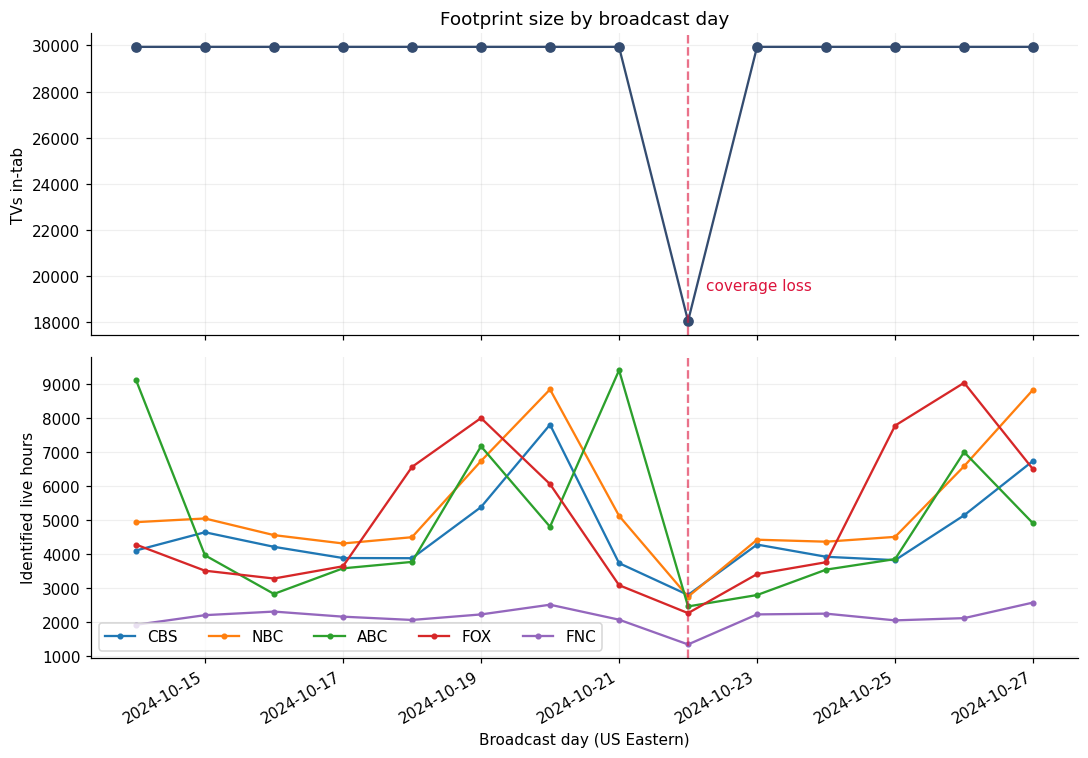

,TVs in-tab,TV-on hours,"Live hours, all recognized networks",TV-on hours per in-tab TV,Live hours per in-tab TV,Flag
2024-10-14,29940,134957.3,44012.5,4.5,1.5,
2024-10-15,29940,133517.9,42248.6,4.5,1.4,
2024-10-16,29940,133188.9,42229.1,4.4,1.4,
2024-10-17,29940,131919.5,42073.9,4.4,1.4,
2024-10-18,29940,131485.0,41482.0,4.4,1.4,
2024-10-19,29940,158878.8,51631.6,5.3,1.7,
2024-10-20,29940,159138.2,51736.7,5.3,1.7,
2024-10-21,29940,136469.8,44834.0,4.6,1.5,
2024-10-22,18041,79361.9,25121.1,4.4,1.4,coverage loss
2024-10-23,29940,132928.5,42339.7,4.4,1.4,


In [9]:
big_daily = live.loc[live.network_code.isin(BIG)].groupby(["broadcast_date","network_code"], observed=True).hours.sum().unstack(fill_value=0).reindex(days,fill_value=0)
fig, axes = plt.subplots(2,1,figsize=(10,7),sharex=True)
axes[0].plot(days,tv_counts,marker="o",color="#344c70")
axes[0].set(ylabel="TVs in-tab",title="Footprint size by broadcast day")
for network in BIG:
    axes[1].plot(days,big_daily[network],marker="o",markersize=3,label=network)
axes[1].set(ylabel="Identified live hours",xlabel="Broadcast day (US Eastern)")
axes[1].legend(ncol=5)
for ax in axes:
    ax.grid(alpha=.2)
    ax.axvline(tv_counts.idxmin(),color="crimson",linestyle="--",alpha=.6)
axes[0].annotate("coverage loss",xy=(tv_counts.idxmin(),tv_counts.min()),
    xytext=(12,20),textcoords="offset points",color="crimson")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
daily_diagnostics = pd.DataFrame({"TVs in-tab": tv_counts,
    "TV-on hours": acr.groupby("broadcast_date").hours.sum().reindex(days),
    "Live hours, all recognized networks": acr.loc[acr.session_type.eq("live") & acr.network_code.notna()].groupby("broadcast_date").hours.sum().reindex(days)})
daily_diagnostics["TV-on hours per in-tab TV"] = daily_diagnostics["TV-on hours"]/tv_counts
daily_diagnostics["Live hours per in-tab TV"] = daily_diagnostics["Live hours, all recognized networks"]/tv_counts
daily_diagnostics["Flag"] = np.where(daily_diagnostics.index==tv_counts.idxmin(),"coverage loss", "")
display(daily_diagnostics)

## Task 4.2 — Spike and broken day

In [10]:
spike_date, spike_network = big_daily.stack().idxmax()
broken_day = tv_counts.idxmin()
spike_schedule = programs.loc[programs.network_code.eq(spike_network) & programs.broadcast_date.eq(spike_date)].copy()
spike_hours = []
for telecast in spike_schedule.itertuples():
    selected = live.loc[live.network_code.eq(spike_network) & live.start_ts.lt(telecast.end_ts) & live.end_ts.gt(telecast.start_ts)]
    overlap = (selected.end_ts.clip(upper=telecast.end_ts)-selected.start_ts.clip(lower=telecast.start_ts)).dt.total_seconds()/3600
    spike_hours.append(overlap.sum())
spike_schedule["ACR live hours"] = spike_hours
display(spike_schedule[["program_name","episode_name","start_ts","ACR live hours"]].sort_values("ACR live hours",ascending=False).head(5))
print("Biggest spike (date, network):", spike_date.strftime("%Y-%m-%d"), spike_network)
print("Broken day (date):", broken_day.strftime("%Y-%m-%d"))

,program_name,episode_name,start_ts,ACR live hours
282,NFL Football,NFL Football: BAL @ TB,2024-10-21 20:15:00,6991.2
278,Local / Syndicated Programming,None,2024-10-21 15:00:00,419.8
272,Good Morning America,"Alessia Cara, Jenny Slate, Dr. Jill Biden",2024-10-21 07:00:00,291.0
280,Local / Syndicated Programming,None,2024-10-21 19:00:00,247.0
283,Local / Syndicated Programming,None,2024-10-21 23:25:00,242.3


Biggest spike (date, network): 2024-10-21 ABC
Broken day (date): 2024-10-22


**Answer:** The biggest identified-live spike is ABC on 2024-10-21: Monday Night Football, Baltimore at Tampa Bay, accounts for 6,991.2 of that network's hours that day. On 2024-10-22 only 18,041 TVs are in-tab, compared with 29,940 on normal days, while TV-on time per available TV stays near 4.40 hours. That looks like a collection or coverage loss rather than a sudden fall in viewing; totals are depressed, and a rating using the smaller denominator can hide the outage or change if the missing TVs are not random. I would flag the day and keep it visible in this report, ask for the missing records, and exclude it from planning estimates unless the vendor can restore or justify it rather than blindly scaling it up.

## Task 5.1 — Sampling error vs bias

In [11]:
selected = ratings.loc[ratings.program_name.str.contains("NFL Football|Hannity|Unsellable Houses",regex=True)].copy()
assert len(selected)==3
hh_counts = hh_days.groupby("broadcast_date").respondent_id.nunique()
p = selected.hh_rating/100
selected["TVs in-tab"] = selected.broadcast_date.map(tv_counts)
selected["Panel HH in-tab"] = selected.broadcast_date.map(hh_counts)
selected["SE footprint"] = np.sqrt(p*(1-p)/selected["TVs in-tab"])*100
selected["SE panel"] = np.sqrt(p*(1-p)/selected["Panel HH in-tab"])*100
selected["TV rating - reference"] = selected["TV HH rating"]-selected.hh_rating
selected["SE panel / footprint"] = selected["SE panel"]/selected["SE footprint"]
display(selected[["program_name","episode_name","TVs in-tab","Panel HH in-tab","SE footprint","SE panel","TV rating - reference","SE panel / footprint"]].assign(
    **{c:selected[c].map("{:.3f}".format) for c in ["SE footprint","SE panel","SE panel / footprint"]}))

,program_name,episode_name,TVs in-tab,Panel HH in-tab,SE footprint,SE panel,TV rating - reference,SE panel / footprint
4,Unsellable Houses,A Doctor's Oasis,29940,3867,0.109,0.303,-1.6,2.783
3,Hannity,Episode 205,29940,3867,0.087,0.241,-1.5,2.783
1,NFL Football,Dallas Cowboys at San Francisco 49ers,29940,3898,0.272,0.754,-11.9,2.771


**Answer:** the footprint's simple-random-sample SE is about 2.8 times smaller than the panel's for these telecasts. Its rating gaps from the reference are still much larger: football is 11.9 points low against an SE of 0.272, Hannity is 1.5 points low against 0.087, and Unsellable Houses is 1.6 points low against 0.109. More observations reduce random sampling error, but they do not repair device coverage, selection bias or recognition errors; these SEs also assume random independent sampling, which the opted-in footprint does not provide.

## Task 5.2 — Answer to the planner

**Answer:** Today I can give you an unweighted one-TV footprint rating of 21.2% for Dallas at San Francisco, clearly labeled as a device-based proxy rather than a national household rating. The reference is 33.1%, so the gap is much larger than the footprint's 0.272-point sampling SE. The feed does not identify who watched or capture the home's other sets. App activity may be logged without identifying its content, and homes without an opted-in TV are absent. TVs without a unique IP match still enter this rating, but we cannot reliably attach their household profiles. Before using the feed for planning, I would validate recognition, resolve the broken day, check linkage coverage, correct the footprint's household skew and account for missed sets against an independent representative source.

## Bonus

In [12]:
football = ratings.loc[ratings.network_code.eq("NBC") & ratings.broadcast_date.eq(pd.Timestamp("2024-10-27"))].iloc[0]
age_lookup = decoded.loc[decoded.attr_id.eq(300)].set_index("respondent_id").value
person_days = daily_weights.loc[daily_weights.resp_type.isin(["R","L"]) & daily_weights.broadcast_date.eq(football.broadcast_date)].copy()
target_ids = person_days.loc[person_days.respondent_id.map(age_lookup).between(25,54),"respondent_id"]
hh_seen = watchers(viewings.loc[viewings.resp_type.eq("H")],football,"respondent_id")
person_seen = watchers(viewings.loc[viewings.resp_type.isin(["R","L"])],football,"respondent_id").intersection(target_ids)
hh_weight = hh_days.loc[hh_days.broadcast_date.eq(football.broadcast_date)].set_index("respondent_id").weight
person_weight = person_days.set_index("respondent_id").weight
hh_audience = hh_weight.reindex(hh_seen).sum()
target_audience = person_weight.reindex(person_seen).sum()
vpvh = target_audience/hh_audience
hh_universe = hh_weight.sum()
target_universe = person_weight.reindex(target_ids).sum()
target_rating = football["TV HH rating"]*vpvh*hh_universe/target_universe
print("VPVH A25-54:", f"{vpvh:.3f}")
print("A25-54 rating (persons):", f"{target_rating:.1f}")
print("Analysis runtime (seconds):", f"{time.perf_counter()-started:.1f}")

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
Analysis runtime (seconds): 42.3


The panel gives 0.513 A25–54 viewers per viewing household, producing an estimated person rating of 11.1% when applied to the TV rating. This assumes the same program's co-viewing and A25–54 composition in footprint homes as in the weighted panel, and uses the panel's same-day household and A25–54 universes. It does not remove the footprint's missing-set, opt-in or recognition bias, so this is a modeled estimate rather than directly observed person viewing